# AAPL buy-and-hold benchmark using Interactive Brokers

This notebook benchmarks a buy-and-hold strategy for **AAPL**, selected because it appears in `equities-list.csv` and has a long trading history. The CSV labels it only as a halal candidate: independently verify current Shariah compliance before making an investment decision.

The data request uses Interactive Brokers **1-hour historical OHLCV bars** during regular trading hours. This is hourly bar data, not historical tick-by-tick data. IBKR's historical API has duration, pacing, permissions, and retention limits; the notebook requests one-year chunks and caches the result locally. It does not guarantee that IBKR can supply every hourly bar back to 2009 for your account or exchange.

## Before running

1. Install dependencies: `pip install ib-insync pandas numpy matplotlib pandas-datareader`
2. Run IBKR Trader Workstation or IB Gateway, enable API connections, and use a market-data-enabled account.
3. Set the host, port, and client ID below. Typical paper ports are 7497 for TWS and 4002 for Gateway; live ports are commonly 7496 and 4001.
4. Run the acquisition cell once. The raw bars are written to `data/AAPL_1h_rth_2009_to_today.csv`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ib_insync import IB, Stock, util
except ImportError as exc:
    raise ImportError('Install ib-insync first: pip install ib-insync') from exc

TICKER = 'AAPL'
EXCHANGE = 'SMART'
CURRENCY = 'USD'
START_DATE = pd.Timestamp('2009-01-03', tz='UTC')
END_DATE = pd.Timestamp.now(tz='UTC')
BAR_SIZE = '1 hour'
WHAT_TO_SHOW = 'TRADES'
USE_RTH = True
CACHE_PATH = Path('data') / f'{TICKER}_1h_rth_2009_to_today.csv'

IB_HOST = '172.27.224.1' #'127.0.0.1'
IB_PORT = 7497
IB_CLIENT_ID = 19

INVESTMENT_2026_DOLLARS = 150.0
# Leave None to use the latest available CPI reading from FRED.
# Set this manually to a CPIAUCSL index value if you need a fixed 2026 CPI.
TARGET_CPI = None

## Download or load the hourly bars

IBKR's `reqHistoricalData` returns bars ending at the requested timestamp. The loop moves backward in one-year windows, with a short pause to reduce pacing risk. If the cache exists, the notebook loads it instead of contacting IBKR.

In [2]:
def normalize_bars(bars):
    frame = util.df(bars)
    if frame.empty:
        return frame
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.set_index('date').sort_index()
    keep = ['open', 'high', 'low', 'close', 'volume', 'average', 'barCount']
    return frame[[column for column in keep if column in frame.columns]]

def download_hourly_bars():
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    util.patchAsyncio()
    ib = IB()
    ib.connect(IB_HOST, IB_PORT, clientId=IB_CLIENT_ID, readonly=True, timeout=20)
    contract = Stock(TICKER, EXCHANGE, CURRENCY)
    ib.qualifyContracts(contract)
    chunks = []
    cursor = END_DATE
    while cursor > START_DATE:
        end_string = cursor.strftime('%Y%m%d %H:%M:%S UTC')
        bars = ib.reqHistoricalData(
            contract, endDateTime=end_string, durationStr='1 Y',
            barSizeSetting=BAR_SIZE, whatToShow=WHAT_TO_SHOW,
            useRTH=USE_RTH, formatDate=2, keepUpToDate=False,
        )
        chunk = normalize_bars(bars)
        if not chunk.empty:
            chunks.append(chunk)
            cursor = chunk.index.min() - pd.Timedelta(hours=1)
        else:
            cursor = cursor - pd.Timedelta(days=365)
        print(f'Fetched through {cursor.date()} ({len(chunk):,} bars in latest request)')
        time.sleep(1.1)
    ib.disconnect()
    if not chunks:
        raise RuntimeError('IBKR returned no bars. Check TWS/Gateway, permissions, contract, and API settings.')
    result = pd.concat(chunks).sort_index()
    result = result.loc[~result.index.duplicated(keep='last')]
    result = result.loc[(result.index >= START_DATE) & (result.index <= END_DATE)]
    result.to_csv(CACHE_PATH, index_label='date')
    return result

def load_cached_bars():
    frame = pd.read_csv(CACHE_PATH, parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

if CACHE_PATH.exists():
    bars = load_cached_bars()
    print(f'Loaded {len(bars):,} cached bars from {CACHE_PATH}')
else:
    bars = download_hourly_bars()
    print(f'Saved {len(bars):,} bars to {CACHE_PATH}')

bars.head()

Loaded 31,038 cached bars from data/AAPL_1h_rth_2009_to_today.csv


,open,high,low,close,volume,average,barCount
date,,,,,,,
2009-01-05 14:30:00+00:00,3.3286,3.3771,3.3111,3.3375,207496800.0,3.350571,42584
2009-01-05 15:00:00+00:00,3.3375,3.3896,3.3218,3.3757,187370400.0,3.356714,42904
2009-01-05 16:00:00+00:00,3.3754,3.3911,3.3643,3.3664,98058800.0,3.378250,23377
2009-01-05 17:00:00+00:00,3.3657,3.4036,3.3650,3.3946,100570400.0,3.387179,20804
2009-01-05 18:00:00+00:00,3.3957,3.4236,3.3882,3.4229,106139600.0,3.405321,24104


In [3]:
# Select the first available regular-session bar on or after Jan 3, 2009,
# and the latest available bar for the current exit.
entry = bars.loc[bars.index >= START_DATE].iloc[0]
exit_bar = bars.iloc[-1]
entry_time = bars.index[bars.index >= START_DATE][0]
exit_time = bars.index[-1]
entry_price = float(entry['close'])
exit_price = float(exit_bar['close'])

print(f'Entry: {entry_time} close=${entry_price:,.2f}')
print(f'Exit:  {exit_time} close=${exit_price:,.2f}')
print(f'Bars:  {len(bars):,}')

Entry: 2009-01-05 14:30:00+00:00 close=$3.34
Exit:  2026-09-11 19:00:00+00:00 close=$332.27
Bars:  31,038


## General statistics

In [4]:
def max_drawdown(prices):
    wealth = prices / prices.iloc[0]
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

hourly_returns = bars['close'].pct_change().dropna()
years = (exit_time - entry_time).total_seconds() / (365.2425 * 24 * 3600)
price_return = exit_price / entry_price - 1.0
cagr = (exit_price / entry_price) ** (1 / years) - 1.0
annualized_volatility = hourly_returns.std() * np.sqrt(252 * 6.5)
stats = pd.Series({
    'observations': len(bars),
    'start_utc': entry_time,
    'end_utc': exit_time,
    'first_close': entry_price,
    'last_close': exit_price,
    'minimum_low': bars['low'].min(),
    'maximum_high': bars['high'].max(),
    'mean_close': bars['close'].mean(),
    'median_close': bars['close'].median(),
    'price_return': price_return,
    'CAGR': cagr,
    'annualized_hourly_volatility': annualized_volatility,
    'max_drawdown': max_drawdown(bars['close']),
    'missing_close_fraction': bars['close'].isna().mean(),
})
display(stats.to_frame('value'))

,value
observations,31038
start_utc,2009-01-05 14:30:00+00:00
end_utc,2026-09-11 19:00:00+00:00
first_close,3.3375
last_close,332.27
minimum_low,2.7946
maximum_high,344.57
mean_close,83.693873
median_close,39.82875
price_return,98.556554


## Buy-and-hold simulation

The amount invested in 2009 is the purchasing-power equivalent of $150 in the target CPI period. CPI is pulled from FRED (`CPIAUCSL`) when available. The trade uses fractional shares so the benchmark measures exposure rather than a whole-share constraint. This is a price-only simulation: commissions, taxes, slippage, dividends, and corporate-action cash flows are excluded.

In [5]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

# Size the 2009 investment so it has the same purchasing power as $150 in the target
# (2026-ish) period: fewer 2009 dollars are needed, since a 2009 dollar bought more.
initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
shares = initial_2009_dollars / entry_price
ending_value = shares * exit_price
nominal_gain = ending_value - initial_2009_dollars
trade_return = ending_value / initial_2009_dollars - 1.0

# ending_value is already denominated in exit-date dollars, and exit_time is "today"
# (~the target CPI period), so it's already expressed in target-period dollars.
# Comparing it directly to INVESTMENT_2026_DOLLARS shows the real, inflation-adjusted
# outcome: did the position grow the original $150 of purchasing power, or shrink it?
ending_value_in_target_dollars = ending_value
real_gain_vs_target_dollars = ending_value_in_target_dollars - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value_in_target_dollars / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'entry_price': entry_price,
    'fractional_shares': shares,
    'exit_price': exit_price,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': trade_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value_in_target_dollars,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))

CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
entry_price,3.337500
fractional_shares,28.507019
exit_price,332.270000
ending_nominal_value,9472.027090
nominal_gain,9376.884915
total_return,98.556554


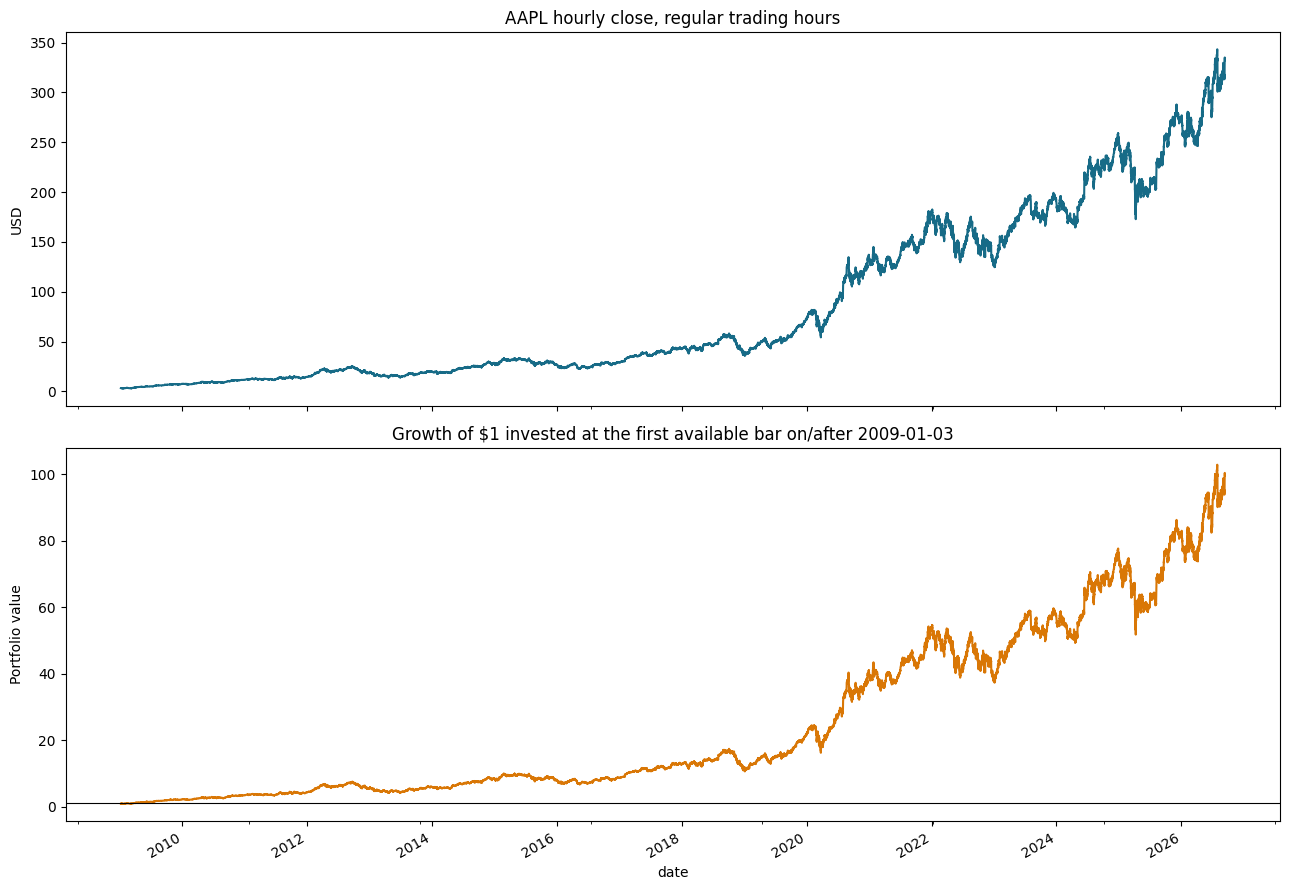

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
bars['close'].plot(ax=axes[0], color='#176b87', title=f'{TICKER} hourly close, regular trading hours')
axes[0].set_ylabel('USD')
wealth = bars['close'] / entry_price
wealth.plot(ax=axes[1], color='#d97706', title='Growth of $1 invested at the first available bar on/after 2009-01-03')
axes[1].set_ylabel('Portfolio value')
axes[1].axhline(1, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## Caveats and next improvements

- Jan 3, 2009 was a Saturday. The entry is therefore the first available regular-session bar on or after that date.
- AAPL's current halal status is not established by this notebook and can change over time.
- Historical hourly bars may be incomplete, unavailable, or subject to IBKR retention and pacing limits. Inspect the printed date range and missingness before trusting results.
- For a total-return benchmark, separately request dividend distributions and handle splits/corporate actions.
- A serious strategy comparison should add transaction costs, taxes, survivorship considerations, and a pre-declared halal screening methodology.

## Monthly performance

Monthly close-to-close returns for the buy-and-hold position, derived from the same hourly bars (last regular-session close of each month). The first and last months are partial (data starts 2009-01-05; the last month runs through the most recent cached bar).

In [7]:
monthly_close = bars['close'].resample('ME').last()
monthly_returns = monthly_close.pct_change().dropna()

table = (monthly_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = monthly_returns.groupby(monthly_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(monthly_returns),
    'positive_months': int((monthly_returns > 0).sum()),
    'pct_positive_months': float((monthly_returns > 0).mean()),
    'avg_monthly_return': float(monthly_returns.mean()),
    'median_monthly_return': float(monthly_returns.median()),
    'best_month': monthly_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(monthly_returns.max()),
    'worst_month': monthly_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(monthly_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-20, vmax=20, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2009,,-0.9,17.6,19.8,7.7,5.1,14.7,2.9,10.2,1.7,6.1,5.4,133.9
2010,-8.9,6.5,14.8,11.1,-1.5,-2.1,2.3,-5.4,16.6,6.0,3.4,3.6,52.9
2011,5.2,4.2,-1.4,0.1,-0.4,-3.5,16.4,-1.5,-0.9,6.2,-5.6,6.0,25.6
2012,12.7,18.8,10.5,-2.6,-1.1,1.1,4.6,8.9,0.3,-10.8,-1.7,-8.9,31.6
2013,-14.6,-3.1,0.2,0.1,1.5,-11.9,14.2,7.7,-2.2,9.6,6.5,0.9,5.3
2014,-10.8,5.1,2.0,9.9,7.3,2.8,2.8,7.2,-1.7,7.2,10.2,-7.1,37.8
2015,6.1,9.7,-3.1,0.6,4.1,-3.8,-3.2,-7.2,-2.1,8.4,-1.0,-11.1,-4.7
2016,-7.7,-0.5,12.7,-14.0,6.5,-4.3,9.0,1.8,6.5,0.5,-2.7,4.8,10.1
2017,4.7,12.9,4.9,-0.0,6.3,-5.7,3.3,10.2,-6.1,9.8,1.6,-1.4,46.1


,value
months,212
positive_months,130
pct_positive_months,0.613208
avg_monthly_return,0.024989
median_monthly_return,0.027217
best_month,2020-08
best_month_return,0.212737
worst_month,2018-11
worst_month_return,-0.183692


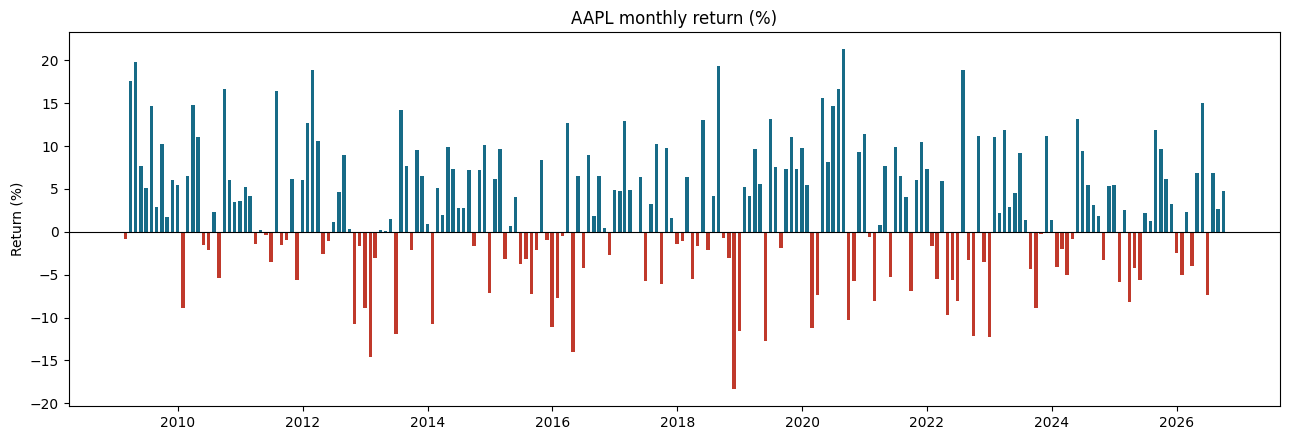

In [8]:
colors = np.where(monthly_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(monthly_returns.index, monthly_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(f'{TICKER} monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()